In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/Car details v3.csv")
df.head()


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
df.shape

(8128, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [5]:
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1202)

In [7]:
df.describe()


,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [8]:
df["fuel"].value_counts()

fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

In [9]:
df["transmission"].value_counts()


transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64

In [10]:
df["seller_type"].value_counts()

seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64

In [11]:
df["owner"].value_counts()

owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64

In [12]:
df["selling_price"].describe()

count    8.128000e+03
mean     6.382718e+05
std      8.062534e+05
min      2.999900e+04
25%      2.549990e+05
50%      4.500000e+05
75%      6.750000e+05
max      1.000000e+07
Name: selling_price, dtype: float64

### Distribution of selling price

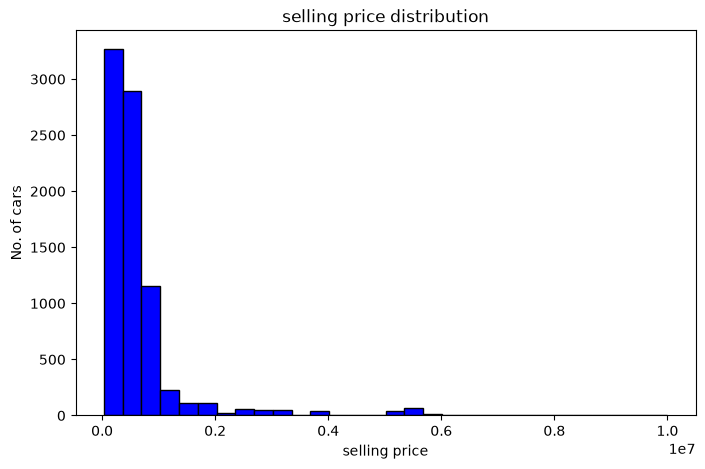

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["selling_price"], bins=30, color="blue", edgecolor="black")
plt.title("selling price distribution")
plt.xlabel("selling price")
plt.ylabel("No. of cars")

plt.show()

### Relationship between year and selling price

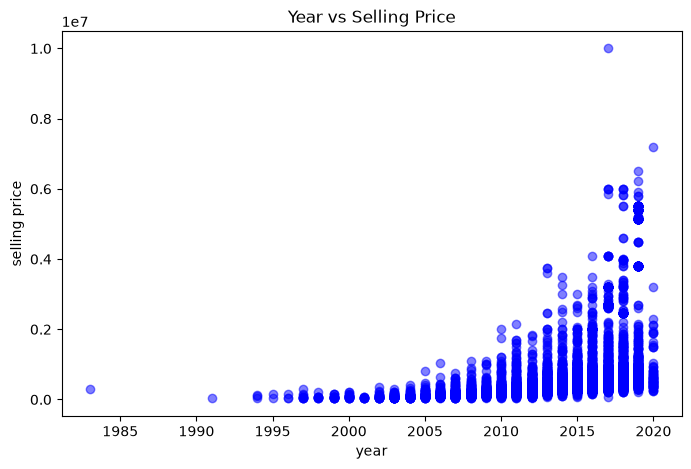

In [14]:
plt.figure(figsize=(8,5))
plt.scatter(df["year"], df["selling_price"], color="blue", alpha=0.5)
plt.title("Year vs Selling Price")
plt.xlabel("year")
plt.ylabel("selling price")
plt.show()

#### km_driven vs selling_price

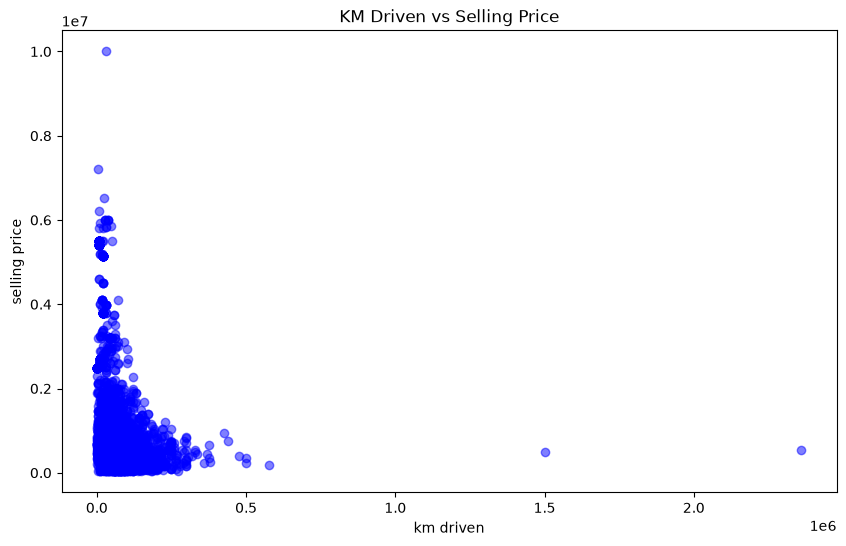

In [15]:
plt.figure(figsize=(10, 6))
plt.scatter(df["km_driven"], df["selling_price"], color="blue", alpha=0.5)
plt.title("KM Driven vs Selling Price")
plt.xlabel("km driven")
plt.ylabel("selling price")
plt.show()

### fuel vs selling_price

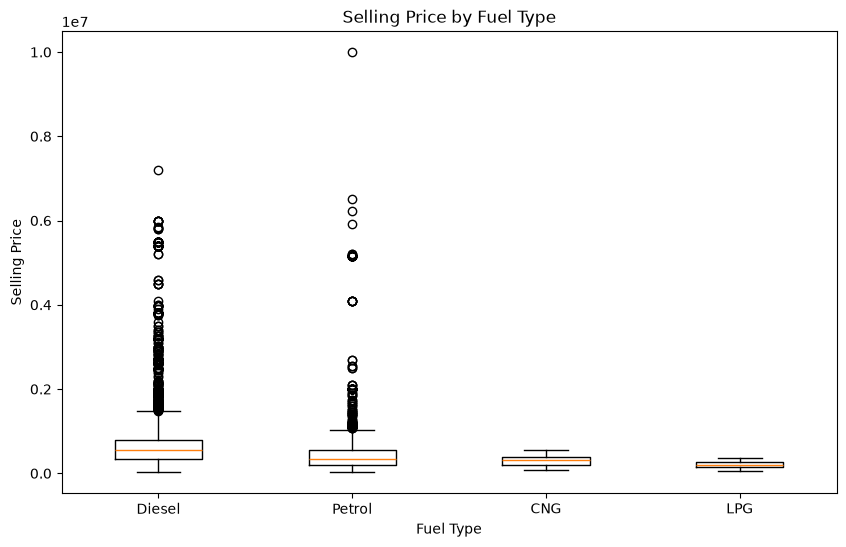

In [16]:
plt.figure(figsize=(10, 6))

plt.boxplot([
    df[df["fuel"] == "Diesel"]["selling_price"],
    df[df["fuel"] == "Petrol"]["selling_price"],
    df[df["fuel"] == "CNG"]["selling_price"],
    df[df["fuel"] == "LPG"]["selling_price"]
])

plt.xticks([1, 2, 3, 4], ["Diesel", "Petrol", "CNG", "LPG"])

plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.title("Selling Price by Fuel Type")

plt.show()

### Transmission vs selling_price

<Figure size 800x500 with 0 Axes>

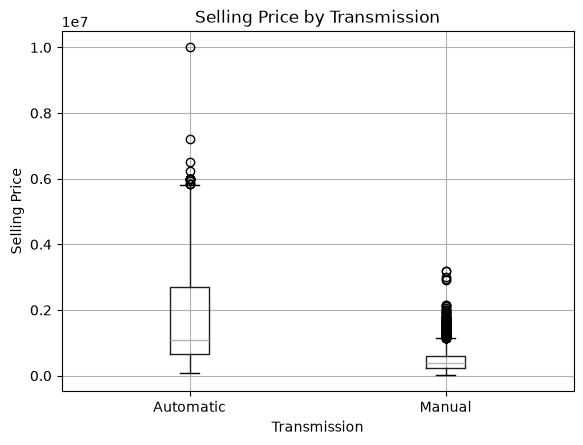

In [17]:
plt.figure(figsize=(8, 5))

df.boxplot(column="selling_price", by="transmission")

plt.xlabel("Transmission")
plt.ylabel("Selling Price")
plt.title("Selling Price by Transmission")

plt.suptitle("")

plt.show()

### owner type vs selling_price

<Figure size 1000x600 with 0 Axes>

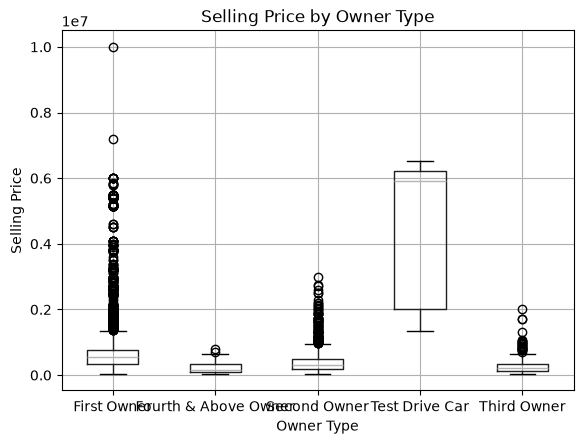

In [18]:
plt.figure(figsize=(10, 6))

df.boxplot(column="selling_price", by="owner")

plt.xlabel("Owner Type")
plt.ylabel("Selling Price")
plt.title("Selling Price by Owner Type")
plt.suptitle("")
plt.show()

In [19]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())


(8128, 13)
name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage              str
engine               str
max_power            str
torque               str
seats            float64
dtype: object
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64


### missing rows of mileage

In [20]:
df[df["mileage"].isnull()].head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
13,Maruti Swift 1.3 VXi,2007,200000,80000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
78,Tata Indica DLS,2003,50000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
87,Maruti Swift VDI BSIV W ABS,2015,475000,78000,Diesel,Dealer,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
119,Maruti Swift VDI BSIV,2010,300000,120000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN


In [21]:
df[df["mileage"].isnull()].isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           221
seats            221
dtype: int64

### max power has 215 missing values of 221 lets see these 6 row

In [22]:
df[
    df["mileage"].isnull() &
    df["max_power"].notnull()
]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
575,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
576,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
1442,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0,NaN,NaN
1443,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0,NaN,NaN
2549,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN
2550,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0,NaN,NaN


In [23]:
df["max_power"].value_counts().head(20)

max_power
74 bhp       377
81.80 bhp    220
88.5 bhp     204
67 bhp       165
46.3 bhp     162
67.1 bhp     151
88.7 bhp     148
67.04 bhp    145
47.3 bhp     141
62.1 bhp     141
70 bhp       141
88.73 bhp    132
81.86 bhp    131
120 bhp      131
140 bhp      128
68 bhp       127
73.9 bhp     124
88.76 bhp    124
55.2 bhp     121
98.6 bhp     118
Name: count, dtype: int64

### removing duplicates

In [24]:
df.drop_duplicates().shape

(6926, 13)

In [25]:
df.shape

(8128, 13)

In [26]:
df=df.drop_duplicates()

In [27]:
df.shape

(6926, 13)

In [28]:
df.duplicated().sum()

np.int64(0)

### missing values

In [29]:
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

In [30]:
(df.isnull().sum() / len(df) * 100).round(2)

name             0.00
year             0.00
selling_price    0.00
km_driven        0.00
fuel             0.00
seller_type      0.00
transmission     0.00
owner            0.00
mileage          3.00
engine           3.00
max_power        2.96
torque           3.02
seats            3.00
dtype: float64

In [31]:
df[df["mileage"].isnull()].isnull()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
13,False,False,False,False,False,False,False,False,True,True,True,True,True
31,False,False,False,False,False,False,False,False,True,True,True,True,True
78,False,False,False,False,False,False,False,False,True,True,True,True,True
87,False,False,False,False,False,False,False,False,True,True,True,True,True
119,False,False,False,False,False,False,False,False,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7740,False,False,False,False,False,False,False,False,True,True,True,True,True
7996,False,False,False,False,False,False,False,False,True,True,True,True,True
8009,False,False,False,False,False,False,False,False,True,True,True,True,True
8068,False,False,False,False,False,False,False,False,True,True,True,True,True


### how many cars are missing all five specifications

In [32]:
df[
    df["mileage"].isnull() &
    df["engine"].isnull() &
    df["max_power"].isnull() &
    df["torque"].isnull() &
    df["seats"].isnull()
].shape

(205, 13)

In [33]:
df[
    df["mileage"].isnull() &
    df["engine"].isnull() &
    df["torque"].isnull() &
    df["seats"].isnull()
][["name", "year", "selling_price", "max_power"]]

,name,year,selling_price,max_power
13,Maruti Swift 1.3 VXi,2007,200000,NaN
31,Fiat Palio 1.2 ELX,2003,70000,NaN
78,Tata Indica DLS,2003,50000,NaN
87,Maruti Swift VDI BSIV W ABS,2015,475000,NaN
119,Maruti Swift VDI BSIV,2010,300000,NaN
...,...,...,...,...
7740,Hyundai Santro Xing XG,2004,70000,NaN
7996,Hyundai Santro LS zipPlus,2000,140000,NaN
8009,Hyundai Santro Xing XS eRLX Euro III,2006,145000,NaN
8068,Ford Figo Aspire Facelift,2017,580000,NaN


In [34]:
df[
    df["mileage"].isnull() &
    df["engine"].isnull() &
    df["torque"].isnull() &
    df["seats"].isnull()
]["max_power"].value_counts(dropna=False)

max_power
NaN    205
0        3
Name: count, dtype: int64

In [35]:
df[
    df["mileage"].isnull() &
    df["engine"].isnull()
]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
13,Maruti Swift 1.3 VXi,2007,200000,80000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
78,Tata Indica DLS,2003,50000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
87,Maruti Swift VDI BSIV W ABS,2015,475000,78000,Diesel,Dealer,Manual,First Owner,NaN,NaN,NaN,NaN,NaN
119,Maruti Swift VDI BSIV,2010,300000,120000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7740,Hyundai Santro Xing XG,2004,70000,70000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
7996,Hyundai Santro LS zipPlus,2000,140000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
8009,Hyundai Santro Xing XS eRLX Euro III,2006,145000,80000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
8068,Ford Figo Aspire Facelift,2017,580000,165000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN


### removed the 208 rows that had almost no useful technical car information from our working dataset.

In [36]:
df = df[
    ~(
        df["mileage"].isnull() &
        df["engine"].isnull() &
        df["torque"].isnull() &
        df["seats"].isnull() &
        (df["max_power"].isnull() | (df["max_power"] == 0))
    )
      ]

In [37]:
df.shape

(6721, 13)

In [38]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          3
engine           3
max_power        0
torque           4
seats            3
dtype: int64

In [39]:
df[df["mileage"].isnull()][["mileage", "engine", "max_power", "torque", "seats"]]

,mileage,engine,max_power,torque,seats
575,NaN,NaN,0,NaN,NaN
1442,NaN,NaN,0,NaN,NaN
2549,NaN,NaN,0,NaN,NaN


In [40]:
df[df["mileage"].isnull()]["max_power"].apply(type)

575     <class 'str'>
1442    <class 'str'>
2549    <class 'str'>
Name: max_power, dtype: object

In [41]:
df = df[
    ~(
        df["mileage"].isnull() &
        df["engine"].isnull() &
        df["torque"].isnull() &
        df["seats"].isnull() &
        (df["max_power"].isnull() | (df["max_power"] == "0"))
    )
]

In [42]:
df.shape

(6718, 13)

In [43]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           1
seats            0
dtype: int64

In [44]:
df[df["torque"].isnull()]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
4933,Maruti Omni CNG,2000,80000,100000,CNG,Individual,Manual,Second Owner,10.9 km/kg,796 CC,bhp,NaN,8.0


In [45]:
df[df["torque"].isnull()][["name", "max_power", "torque"]]

,name,max_power,torque
4933,Maruti Omni CNG,bhp,NaN


In [46]:
df = df[df["torque"].notnull()]

In [47]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
dtype: int64

### Data type coversion/feature extraction

In [48]:
print(df["mileage"].head(10).tolist())
print(df["engine"].head(10).tolist())
print(df["max_power"].head(10).tolist())
print(df["torque"].head(10).tolist())

['23.4 kmpl', '21.14 kmpl', '17.7 kmpl', '23.0 kmpl', '16.1 kmpl', '20.14 kmpl', '17.3 km/kg', '16.1 kmpl', '23.59 kmpl', '20.0 kmpl']
['1248 CC', '1498 CC', '1497 CC', '1396 CC', '1298 CC', '1197 CC', '1061 CC', '796 CC', '1364 CC', '1399 CC']
['74 bhp', '103.52 bhp', '78 bhp', '90 bhp', '88.2 bhp', '81.86 bhp', '57.5 bhp', '37 bhp', '67.1 bhp', '68.1 bhp']
['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)', '113.75nm@ 4000rpm', '7.8@ 4,500(kgm@ rpm)', '59Nm@ 2500rpm', '170Nm@ 1800-2400rpm', '160Nm@ 2000rpm']


### Extract numbers from mileage, engine, max_power

In [49]:
df["mileage"] = df["mileage"].str.extract(r"([\d.]+)").astype(float)

df["engine"] = df["engine"].str.extract(r"([\d.]+)").astype(float)

df["max_power"] = df["max_power"].str.extract(r"([\d.]+)").astype(float)

In [50]:
df[["mileage", "engine", "max_power"]].head()

,mileage,engine,max_power
0,23.40,1248.0,74.00
1,21.14,1498.0,103.52
2,17.70,1497.0,78.00
3,23.00,1396.0,90.00
4,16.10,1298.0,88.20


In [51]:
df[["mileage", "engine", "max_power"]].dtypes

mileage      float64
engine       float64
max_power    float64
dtype: object

### torque

In [52]:
df["torque"].value_counts().head(20)

torque
190Nm@ 2000rpm               472
200Nm@ 1750rpm               398
90Nm@ 3500rpm                353
62Nm@ 3000rpm                160
114Nm@ 4000rpm               156
113Nm@ 4200rpm               139
160Nm@ 2000rpm               131
69Nm@ 3500rpm                131
330Nm@ 1600-2800rpm          114
74.5Nm@ 4000rpm              111
59Nm@ 2500rpm                107
195Nm@ 1400-2200rpm           94
219.7Nm@ 1500-2750rpm         88
114.7Nm@ 4000rpm              85
20.4@ 1400-3400(kgm@ rpm)     77
290Nm@ 1800-2800rpm           74
114Nm@ 3500rpm                71
250Nm@ 1500-2500rpm           70
72Nm@ 4386rpm                 70
259.9Nm@ 1900-2750rpm         68
Name: count, dtype: int64

In [53]:
df["torque"].str.contains("kgm", case=False, na=False).sum()

np.int64(481)

In [54]:
df["torque_nm"] = df["torque"].str.extract(r"([\d.]+)").astype(float)

In [55]:
df[["torque", "torque_nm"]].head(10)

,torque,torque_nm
0,190Nm@ 2000rpm,190.00
1,250Nm@ 1500-2500rpm,250.00
2,"12.7@ 2,700(kgm@ rpm)",12.70
3,22.4 kgm at 1750-2750rpm,22.40
4,"11.5@ 4,500(kgm@ rpm)",11.50
5,113.75nm@ 4000rpm,113.75
6,"7.8@ 4,500(kgm@ rpm)",7.80
7,59Nm@ 2500rpm,59.00
8,170Nm@ 1800-2400rpm,170.00
9,160Nm@ 2000rpm,160.00


In [56]:
kgm_rows = df["torque"].str.contains("kgm", case=False, na=False)

df.loc[kgm_rows, "torque_nm"] = df.loc[kgm_rows, "torque_nm"] * 9.81

In [57]:
df.loc[kgm_rows, "torque_nm"]

2       124.587
3       219.744
4       112.815
6        76.518
17      219.744
         ...   
8082    159.903
8104    132.435
8105    110.853
8113    200.124
8124    235.440
Name: torque_nm, Length: 481, dtype: float64

In [58]:
df[kgm_rows][["torque", "torque_nm"]].head()

,torque,torque_nm
2,"12.7@ 2,700(kgm@ rpm)",124.587
3,22.4 kgm at 1750-2750rpm,219.744
4,"11.5@ 4,500(kgm@ rpm)",112.815
6,"7.8@ 4,500(kgm@ rpm)",76.518
17,22.4 kgm at 1750-2750rpm,219.744


In [59]:
df["torque_nm"].isnull().sum()

np.int64(0)

In [60]:
df[["mileage", "engine", "max_power", "torque_nm"]].dtypes

mileage      float64
engine       float64
max_power    float64
torque_nm    float64
dtype: object

### feature engineering 

### -->feature construction of car year


In [61]:
df["car_age"] = 2026 - df["year"]

In [62]:
df[["year", "car_age"]].head(10)

,year,car_age
0,2014,12
1,2014,12
2,2006,20
3,2010,16
4,2007,19
5,2017,9
6,2007,19
7,2001,25
8,2011,15
9,2013,13


### feature extraction of brand from name

In [63]:
df["brand"] = df["name"].str.split().str[0]

In [64]:
df[["brand", "name"]].head(10)

,brand,name
0,Maruti,Maruti Swift Dzire VDI
1,Skoda,Skoda Rapid 1.5 TDI Ambition
2,Honda,Honda City 2017-2020 EXi
3,Hyundai,Hyundai i20 Sportz Diesel
4,Maruti,Maruti Swift VXI BSIII
5,Hyundai,Hyundai Xcent 1.2 VTVT E Plus
6,Maruti,Maruti Wagon R LXI DUO BSIII
7,Maruti,Maruti 800 DX BSII
8,Toyota,Toyota Etios VXD
9,Ford,Ford Figo Diesel Celebration Edition


### handle mileage


In [65]:
raw_df = pd.read_csv("../data/raw/Car details v3.csv")

In [71]:
raw_df["mileage"].str.extract(r"(kmpl|km/kg)", expand=False).value_counts()

mileage
kmpl     7819
km/kg      88
Name: count, dtype: int64

In [72]:
raw_df[raw_df["mileage"].str.contains("km/kg", na=False)]["fuel"].value_counts()

fuel
CNG    53
LPG    35
Name: count, dtype: int64

In [73]:
df["mileage_unit"] = raw_df.loc[df.index, "mileage"].str.extract(
    r"(kmpl|km/kg)", expand=False
)

In [74]:
df["mileage_unit"].value_counts()

mileage_unit
kmpl     6631
km/kg      86
Name: count, dtype: int64

In [75]:
df[["mileage", "mileage_unit", "fuel"]].head(10)

,mileage,mileage_unit,fuel
0,23.40,kmpl,Diesel
1,21.14,kmpl,Diesel
2,17.70,kmpl,Petrol
3,23.00,kmpl,Diesel
4,16.10,kmpl,Petrol
5,20.14,kmpl,Petrol
6,17.30,km/kg,LPG
7,16.10,kmpl,Petrol
8,23.59,kmpl,Diesel
9,20.00,kmpl,Diesel


### Decide which columns are actually useful

In [77]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque',
       'seats', 'torque_nm', 'car_age', 'brand', 'mileage_unit'],
      dtype='str')

In [78]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,car_age,brand,mileage_unit
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,190.000,12,Maruti,kmpl
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,250.000,12,Skoda,kmpl
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,124.587,20,Honda,kmpl
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,219.744,16,Hyundai,kmpl
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,112.815,19,Maruti,kmpl


### outlier check

In [79]:
df[[
    "selling_price",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "torque_nm",
    "seats"
]].describe()

,selling_price,km_driven,mileage,engine,max_power,torque_nm,seats
count,6.717000e+03,6.717000e+03,6717.000000,6717.000000,6717.000000,6717.000000,6717.000000
mean,5.263860e+05,7.339834e+04,19.466585,1430.985857,87.766100,175.188252,5.434271
std,5.235504e+05,5.870328e+04,4.048102,493.469198,31.724555,115.322342,0.983805
min,2.999900e+04,1.000000e+00,0.000000,624.000000,32.800000,47.088000,2.000000
25%,2.500000e+05,3.800000e+04,16.800000,1197.000000,67.100000,110.000000,5.000000
50%,4.200000e+05,6.820300e+04,19.440000,1248.000000,81.830000,160.000000,5.000000
75%,6.500000e+05,1.000000e+05,22.500000,1498.000000,100.000000,200.124000,5.000000
max,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,3727.800000,14.000000


In [80]:
df[
    (df["mileage"] == 0) |
    (df["km_driven"] > 500000) |
    (df["torque_nm"] > 1000)
][[
    "name",
    "year",
    "selling_price",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "torque_nm",
    "fuel"
]]

,name,year,selling_price,km_driven,mileage,engine,max_power,torque_nm,fuel
604,Tata Sumo CX 10 Str BSIV,2011,175000,20000,12.2,1948.0,68.00,1128.150,Diesel
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,0.0,1172.0,65.00,96.138,Petrol
778,Ford Endeavour Hurricane Limited Edition,2013,1075000,110000,12.8,2953.0,156.00,3727.800,Diesel
785,Hyundai Santro Xing GL,2009,120000,90000,0.0,1086.0,62.00,96.100,Petrol
1211,Maruti SX4 Vxi BSIII,2007,160000,120000,15.0,1586.0,104.68,1422.450,Petrol
1649,Hyundai Santro Xing GL,2008,105000,128000,0.0,1086.0,62.00,96.100,Petrol
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,0.0,2987.0,165.00,510.000,Diesel
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,15.1,2179.0,140.00,330.000,Diesel
2086,Tata Sumo EX 10/7 Str BSIII,2012,200000,67500,12.2,1948.0,68.00,1128.150,Diesel
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,0.0,2179.0,115.00,400.000,Diesel


In [81]:
df.loc[
    df["torque_nm"] > 1000,
    ["name", "torque", "torque_nm"]
]

,name,torque,torque_nm
604,Tata Sumo CX 10 Str BSIV,"115@ 2,500(kgm@ rpm)",1128.15
778,Ford Endeavour Hurricane Limited Edition,380Nm(38.7kgm)@ 2500rpm,3727.80
1211,Maruti SX4 Vxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
2086,Tata Sumo EX 10/7 Str BSIII,"115@ 2,500(kgm@ rpm)",1128.15
2289,Maruti SX4 Zxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
2314,Maruti SX4 Zxi with Leather BSIII,"145@ 4,100(kgm@ rpm)",1422.45
2421,Ford Ikon 1.6 Nxt,130@ 2500(kgm@ rpm),1275.30
2880,Ford Ikon 1.6 EXi NXt,130@ 2500(kgm@ rpm),1275.30
4149,Maruti SX4 Vxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
4309,Maruti SX4 Vxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45


In [82]:
import numpy as np

df["torque_nm"] = np.nan

# Values explicitly given in Nm
nm_rows = df["torque"].str.contains("Nm", case=False, na=False)

df.loc[nm_rows, "torque_nm"] = (
    df.loc[nm_rows, "torque"]
    .str.extract(r"([\d.]+)", expand=False)
    .astype(float)
)

# Values given in kgm
kgm_rows = (
    df["torque"].str.contains("kgm", case=False, na=False)
    & ~nm_rows
)

df.loc[kgm_rows, "torque_nm"] = (
    df.loc[kgm_rows, "torque"]
    .str.extract(r"([\d.]+)", expand=False)
    .astype(float)
    * 9.81
)

In [83]:
df.loc[
    df["torque_nm"] > 1000,
    ["name", "torque", "torque_nm"]
]

,name,torque,torque_nm
604,Tata Sumo CX 10 Str BSIV,"115@ 2,500(kgm@ rpm)",1128.15
1211,Maruti SX4 Vxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
2086,Tata Sumo EX 10/7 Str BSIII,"115@ 2,500(kgm@ rpm)",1128.15
2289,Maruti SX4 Zxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
2314,Maruti SX4 Zxi with Leather BSIII,"145@ 4,100(kgm@ rpm)",1422.45
2421,Ford Ikon 1.6 Nxt,130@ 2500(kgm@ rpm),1275.30
2880,Ford Ikon 1.6 EXi NXt,130@ 2500(kgm@ rpm),1275.30
4149,Maruti SX4 Vxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
4309,Maruti SX4 Vxi BSIII,"145@ 4,100(kgm@ rpm)",1422.45
4454,Tata Sumo GX 7 Str BSII,115@ 2500(kgm@ rpm),1128.15


In [84]:
# Fix suspicious torque values caused by incorrect kgm labels
suspicious_torque = df["torque_nm"] > 1000

df.loc[suspicious_torque, "torque_nm"] = (
    df.loc[suspicious_torque, "torque"]
    .str.extract(r"([\d.]+)", expand=False)
    .astype(float)
)

In [85]:
df.loc[
    df["torque_nm"] > 1000,
    ["name", "torque", "torque_nm"]
]

,name,torque,torque_nm


In [86]:
df["torque_nm"].describe()

count    6707.000000
mean      170.864357
std        84.529155
min        47.088000
25%       110.000000
50%       160.000000
75%       200.124000
max       789.000000
Name: torque_nm, dtype: float64

In [87]:
df[df["torque_nm"].isnull()][
    ["name", "torque"]
]

,name,torque
140,Skoda Superb LK 1.8 TSI AT,250@ 1250-5000rpm
1676,Mercedes-Benz M-Class ML 350 4Matic,510@ 1600-2400
2000,Honda Jazz Select Edition Active,110(11.2)@ 4800
4373,Skoda Octavia Classic 1.9 TDI MT,210 / 1900
5572,Skoda Octavia Classic 1.9 TDI MT,210 / 1900
5785,Skoda Octavia Ambiente 1.9 TDI MT,210 / 1900
6418,Skoda Octavia Ambiente 1.9 TDI MT,210 / 1900
7154,Skoda Octavia Rider 1.9 AT TDI,210 / 1900
7296,Skoda Octavia Ambiente 1.9 TDI,210 / 1900
7532,Skoda Octavia Ambiente 1.9 TDI MT,210 / 1900


In [88]:
missing_torque = df["torque_nm"].isnull()

df.loc[missing_torque, "torque_nm"] = (
    df.loc[missing_torque, "torque"]
    .str.extract(r"([\d.]+)", expand=False)
    .astype(float)
)

In [89]:
df["torque_nm"].isnull().sum()

np.int64(0)

In [90]:
df["torque_nm"].describe()  

count    6717.000000
mean      170.958351
std        84.585672
min        47.088000
25%       110.000000
50%       160.000000
75%       200.124000
max       789.000000
Name: torque_nm, dtype: float64

In [91]:
df[df["mileage"] == 0][
    ["name", "year", "selling_price", "fuel", "mileage", "engine", "max_power"]
]

,name,year,selling_price,fuel,mileage,engine,max_power
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,Petrol,0.0,1172.0,65.00
785,Hyundai Santro Xing GL,2009,120000,Petrol,0.0,1086.0,62.00
1649,Hyundai Santro Xing GL,2008,105000,Petrol,0.0,1086.0,62.00
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,Diesel,0.0,2987.0,165.00
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,Diesel,0.0,2179.0,115.00
2366,Hyundai Santro Xing (Non-AC),2010,110000,Petrol,0.0,1086.0,62.10
2725,Hyundai Santro Xing (Non-AC),2013,184000,Petrol,0.0,1086.0,62.10
5276,Hyundai Santro Xing GL,2008,175000,Petrol,0.0,1086.0,62.00
5843,Volkswagen Polo GT TSI BSIV,2014,574000,Petrol,0.0,1197.0,103.25
5846,Volkswagen Polo GT TSI BSIV,2014,575000,Petrol,0.0,1197.0,103.25


In [92]:
df = df[df["mileage"] > 0]


In [93]:
df["mileage"].describe()

count    6702.000000
mean       19.510154
std         3.946346
min         9.000000
25%        16.800000
50%        19.490000
75%        22.540000
max        42.000000
Name: mileage, dtype: float64

In [94]:
df.shape

(6702, 17)

In [95]:
df[df["km_driven"] > 500000][
    ["name", "year", "selling_price", "km_driven", "fuel"]
]

,name,year,selling_price,km_driven,fuel
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel
3486,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol
3508,Maruti Wagon R LXI Minor,2010,194000,577414,Petrol


In [96]:
df = df[df["km_driven"] <= 1_000_000]

In [97]:
df["km_driven"].describe()

count      6700.000000
mean      72872.881940
std       48647.131835
min           1.000000
25%       38000.000000
50%       68221.500000
75%      100000.000000
max      577414.000000
Name: km_driven, dtype: float64

In [98]:
df.shape

(6700, 17)

In [99]:
df[df["max_power"] > 300][
    ["name", "year", "selling_price", "max_power", "engine", "fuel"]
]

,name,year,selling_price,max_power,engine,fuel
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,400.0,1969.0,Petrol


In [100]:
df[df["seats"] >= 10][
    ["name", "year", "selling_price", "seats", "fuel"]
]

,name,year,selling_price,seats,fuel
604,Tata Sumo CX 10 Str BSIV,2011,175000,10.0,Diesel
795,Chevrolet Tavera Neo 3 LS 10 Str,2016,409999,10.0,Diesel
2086,Tata Sumo EX 10/7 Str BSIII,2012,200000,10.0,Diesel
2331,Chevrolet Tavera Neo 3 10 Seats BSIII,2014,600000,10.0,Diesel
3283,Chevrolet Tavera Neo 3 LS 10 Seats BSIII,2015,580000,10.0,Diesel
3714,Chevrolet Tavera B3 LT L1 10 Seats BSIII,2005,160000,10.0,Diesel
3794,Chevrolet Tavera LS B3 10 Seats BSII,2006,225000,10.0,Diesel
4112,Tata Sumo SE Plus BSII,2000,95000,10.0,Diesel
4182,Chevrolet Tavera B1-10 seats BSII,2010,280000,10.0,Diesel
4575,Tata Winger Deluxe - Flat Roof (Non-AC),2010,235000,14.0,Diesel


In [101]:
df.shape

(6700, 17)

In [102]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
torque_nm        0
car_age          0
brand            0
mileage_unit     0
dtype: int64

In [105]:
df[["name", "brand", "fuel", "seller_type", "transmission", "owner", "mileage_unit"]].nunique()

name            1973
brand             31
fuel               4
seller_type        3
transmission       2
owner              5
mileage_unit       2
dtype: int64

In [104]:
df.dtypes

name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage          float64
engine           float64
max_power        float64
torque               str
seats            float64
torque_nm        float64
car_age            int64
brand             object
mileage_unit         str
dtype: object